In [1]:
import numpy as np
import matplotlib.pyplot as plt
# import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import fastplotlib as fpl
import tifffile
from skophys.viz_helpers import spatial_to_rgba
from skophys.datasets import ARProcess, ARProcessMovie

%matplotlib inline

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/pygfx/utils/_dirs.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
def remove_duplicate_rows(matrix):
    matrix = np.array(matrix)
    unique_matrix = np.unique(matrix, axis=1)
    return unique_matrix

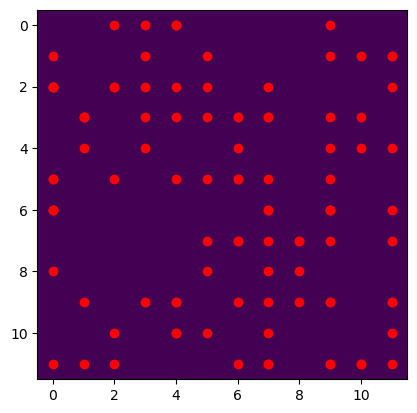

In [3]:
fig_label = "sim"

n_lags = 4
lag_time = 1


simulation = True
obs_noise_level = 0.1

dims = 12, 12
source_size = 1
n_sources = 10
# np.random.seed(3)
np.random.seed(5)
locs = (np.random.rand(100, 2) * dims[0]).clip(0).astype(int)
locs = remove_duplicate_rows(locs)

# dims = 14, 14
# source_size = 2
# n_sources = 2
# locs = (np.random.rand(2, 2) * dims[0]).clip(0).astype(int)
# locs[0,0] = 8
# locs[0,1] = 6
# locs[1,0] = 8
# locs[1,1] = 8

plt.imshow(np.zeros(dims))
plt.scatter(locs[:, 0], locs[:, 1], c="r")
plt.show()

# simulation = False
# n_sources = 15
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif"


r.shape = (6,)
z.shape = (6, 6)
spatial_footprints.shape = (10, 12, 12)
added_source = 10


<Axes: >

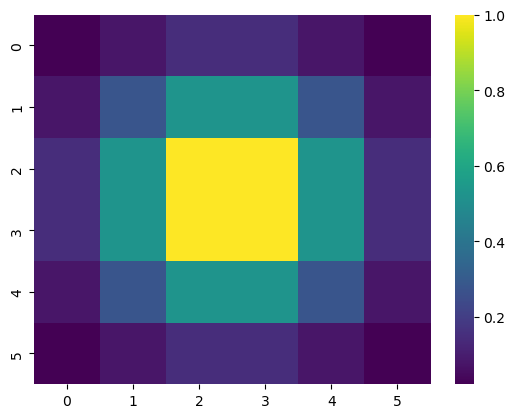

In [4]:
S = ARProcessMovie(
    n_timepoints=1_000,
    n_components=n_sources,
    ar_noise_sigma=0.1,
    obs_noise_sigma=obs_noise_level,
    movie_dims=dims,
    component_size=source_size,
    component_locs=locs,
)

sns.heatmap(S.kernel, cmap="viridis")

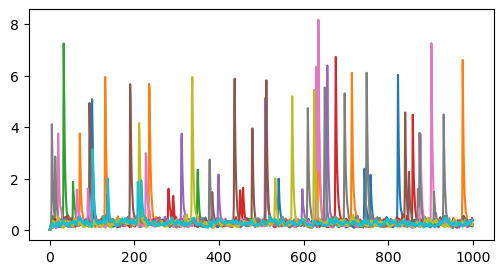

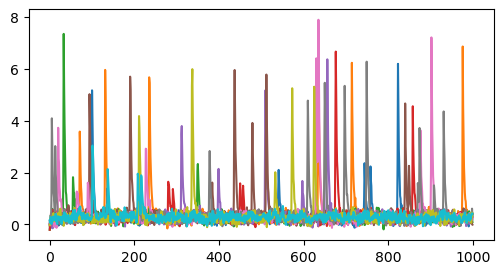

In [5]:
traces = S.traces
traces_obs = S.traces_obs

fig, ax = plt.subplots(figsize=(6, 3))
for src in range(0,len(traces)):
    ax.plot(traces[src])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_trace_{fig_label}.png')
plt.show()

fig, ax = plt.subplots(figsize=(6, 3))
for src in range(0,len(traces_obs)):
    ax.plot(traces_obs[src])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/observed_trace_{fig_label}.png')
plt.show()

In [6]:
source_footprints = S.source_footprints
print (f"source_footprints.shape = {source_footprints.shape}")

source_footprints.shape = (10, 12, 12)


In [7]:
movie = S.movie
# Convert the data type to float32
movie = movie.astype(np.float32)
print (movie.shape)

(1000, 12, 12)


In [8]:
if not simulation:

    # movie = tifffile.imread(path)[:]
    movie = tifffile.imread(path)[:, ::2, ::2]
    # movie = tifffile.imread(path)[::2, ::2, ::2]

    # Convert the data type to float32
    movie = movie.astype(np.float32)
    
    # n_pix_x = movie.shape[2]
    # n_pix_y = movie.shape[1]
    # n_frame = movie.shape[0]
    
    # n_pix_x_small = int(n_pix_x/3.)
    # n_pix_y_small = int(n_pix_y/3.)
    # small_movie = movie[:, n_pix_y_small:2*n_pix_y_small, n_pix_x_small:2*n_pix_x_small]
    
    # # Convert the data type to float32
    # movie = small_movie.astype(np.float32)
    
    print (movie.shape)

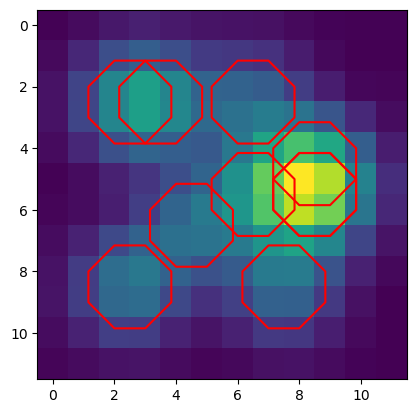

In [9]:
# fpl.ImageWidget(movie).show()

plt.imshow(movie.mean(axis=0))
if simulation:
    truth_levels = [0.60]
    for src in range(0,n_sources):
        plt.contour(source_footprints[src], levels=truth_levels, colors='r')
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_image_{fig_label}.png')

In [10]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie)

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


X.shape = (144, 1000)
P.shape = (5, 144, 996)


<Axes: >

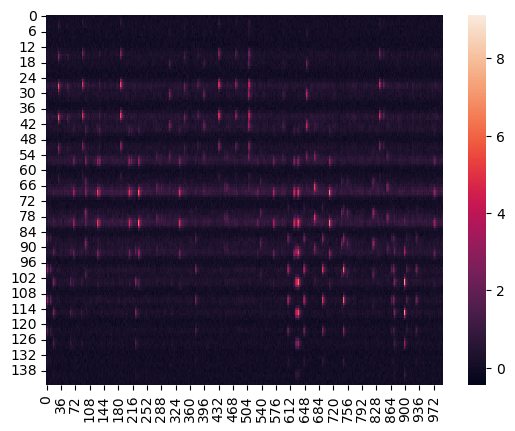

In [11]:
n_pixels = X.shape[0]
n_time_steps = X.shape[1]

P = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    for col in range(0,n_time_steps-n_lags*lag_time):
        P[lag,:,col] = X[:,col+lag*lag_time]

print (f"X.shape = {X.shape}")
print (f"P.shape = {P.shape}")
sns.heatmap(P[n_lags,:, :])

In [12]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eig(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

In [13]:
def covariance_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    N = X.shape[1]
    COV = X @ X.T / float(N)
    
    return COV

In [14]:
def whitened_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    COV = covariance_matrix(X)
    S, U = eigen_decomposition(COV)

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_sqrt_S = np.diag(1.0 / np.sqrt(S + epsilon))

    # whitening matrix
    W = U @ inv_sqrt_S @ U.T

    # whitened data
    Xw = W @ X

    return Xw

eigenvectors.shape = (144, 144)
eigenvectors.shape = (144, 144)
eigenvectors.shape = (144, 144)
eigenvectors.shape = (144, 144)
eigenvectors.shape = (144, 144)
P.shape = (5, 144, 996)
Pw.shape = (5, 144, 996)
[[ 9.98808688e-01 -4.92634443e-05 -1.79643865e-05 ...  3.01264625e-05
   4.42022427e-06  6.10092717e-06]
 [-4.92634443e-05  9.98747637e-01 -7.78632784e-05 ...  2.93156419e-05
  -5.55311462e-05  8.58022534e-06]
 [-1.79643865e-05 -7.78632784e-05  9.98819168e-01 ... -1.57882248e-05
  -1.48807883e-05  5.53805595e-05]
 ...
 [ 3.01264625e-05  2.93156419e-05 -1.57882248e-05 ...  9.98782741e-01
   1.55714525e-06 -3.92849577e-05]
 [ 4.42022427e-06 -5.55311462e-05 -1.48807883e-05 ...  1.55714525e-06
   9.98827507e-01  2.27446852e-05]
 [ 6.10092717e-06  8.58022534e-06  5.53805595e-05 ... -3.92849577e-05
   2.27446852e-05  9.98722088e-01]]


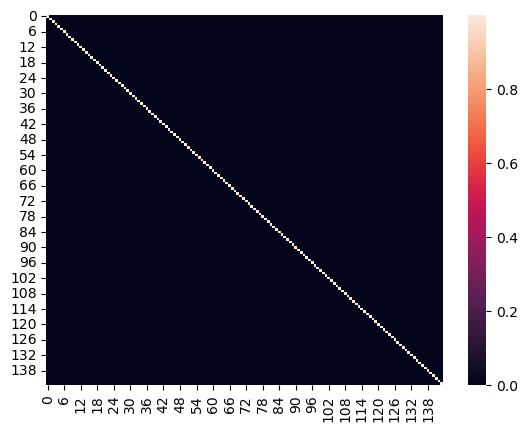

In [15]:
Pw = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    Pw[lag,:,:] = whitened_matrix(P[lag,:,:])
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")

# verify that Pw is whitened data
COV = covariance_matrix(Pw[0,:,:])
print (COV)
sns.heatmap(COV[:, :])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/pca_cov_{fig_label}.png')

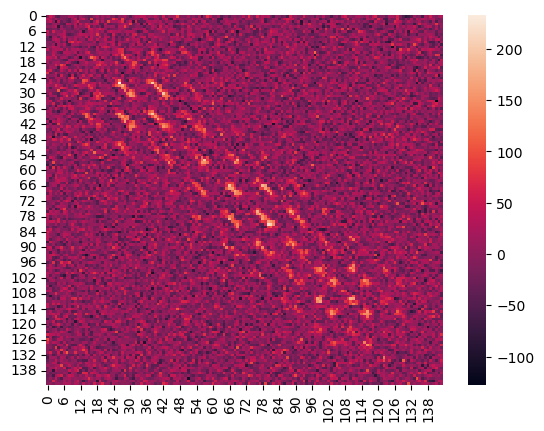

In [16]:
if n_lags>0:
    cross_correlation = Pw[1,:,:] @ Pw[0,:,:].T
    sns.heatmap(cross_correlation[:, :])
    # iw = fpl.ImageWidget(cross_correlation, cmap="viridis", histogram_widget=False)
    # iw.show()

In [17]:
if n_lags==0:
    Z = Pw[0].copy()
if n_lags==1:
    Z = np.vstack((Pw[0], Pw[1]))
if n_lags==2:
    Z = np.vstack((Pw[0], Pw[1], Pw[2]))
if n_lags==3:
    Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3]))
if n_lags==4:
    Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3], Pw[4]))
if n_lags==5:
    Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3], Pw[4], Pw[5]))
ZZT = covariance_matrix(Z)

In [18]:
# S, U = eigen_decomposition(ZZT)
S, U = eigen_decomposition(P[0] @ P[0].T)

eigenvectors.shape = (144, 144)


U.shape = (144, 144)


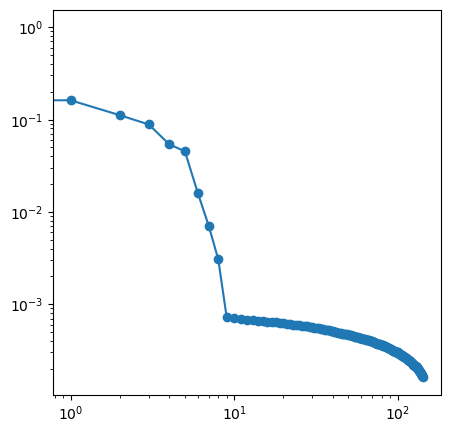

In [19]:
print (f"U.shape = {U.shape}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(S[:] / S.max(),'o-')
ax.set_yscale('log')
ax.set_xscale('log')
# plt.ylim(0.15, 1.5)
plt.show()

[0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


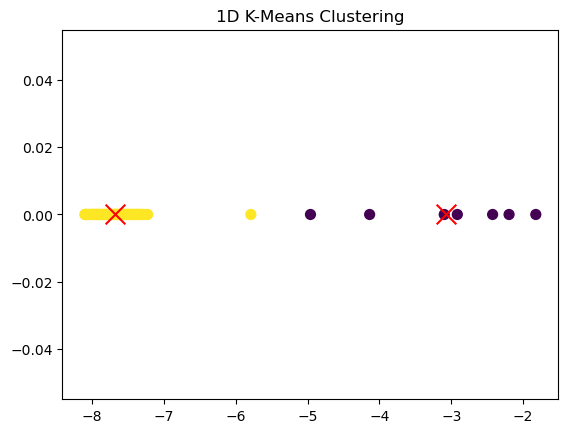

k = 10


In [20]:
def kmeans_1d(data, k, max_iters=100, tol=1e-4):
    # Randomly initialize k cluster centers
    centroids = np.random.choice(data, k, replace=False)
    centroids[0] = np.max(data)
    for entry in range(1,k):
        centroids[entry] = np.min(data)

    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        distances = np.abs(data[:, np.newaxis] - centroids[np.newaxis, :])
        labels = np.argmin(distances, axis=1)

        # Compute new centroids
        new_centroids = np.array([data[labels == i].mean() if np.any(labels == i) else centroids[i] 
                                  for i in range(k)])

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids

    return labels, centroids

max_entries = 100
# labels, centroids = kmeans_1d((S[1:max_entries] / S.max()), k=2)
labels, centroids = kmeans_1d(np.log(S[1:max_entries] / S.max()), k=2)
print (labels)

# Plotting
plt.scatter(np.log(S[1:max_entries] / S.max()), np.zeros_like(S[1:max_entries]), c=labels, cmap='viridis', s=50)
plt.scatter(centroids, np.zeros_like(centroids), color='red', marker='x', s=200)
plt.title('1D K-Means Clustering')
plt.show()

if not simulation:
    n_sources = int(np.sum(labels == 0))
    
k = n_sources
print (f"k = {k}")

In [21]:
# Uk = U[:,:k]
# Sk = np.diag(np.sqrt(S[:k]))
# print (f"Uk.shape = {Uk.shape}")

# Y = Sk @ Uk.T
# print (f"Y.shape = {Y.shape}")

In [22]:
# Y_sum = np.zeros((k,n_pixels))
# for lag in range(0,n_lags):
#     Y_sum[:,:] += Y[:,lag*n_pixels:(lag+1)*n_pixels]
    

# image_array = []
# for cluster in range(0,k):
#     snapshot = unvec.transform(Y_sum[cluster,:])
#     image_array += [snapshot]

# fig, ax = plt.subplots(k, 1, figsize=(6.4, k * 4.8))
# for row in range(0,k):
#     ax[row].imshow(image_array[row])
# plt.show()

# iw = fpl.ImageWidget(image_array, cmap="viridis", histogram_widget=False)
# iw.show()

In [23]:
# S, U = eigen_decomposition(ZZT)

In [24]:
from tqdm.notebook import tqdm

eta = 0.1
error_stop = 1e-4
n_iterations = 5_000
error_log = np.zeros(n_iterations)

# S, U = eigen_decomposition(ZZT)
# Uk = U[:,:k]
# Sk = np.diag(np.sqrt(S[:k]))
# H = np.abs(Uk @ Sk)
H_init = 2 * np.sqrt(np.mean(np.mean(ZZT) / k)) * np.random.rand(ZZT.shape[0], k)
H = H_init

N = H.shape[0]

epsilon = 1e-10
epsilon_mtx = np.ones_like(H@H.T@H) * epsilon

# beta = 0.001
# beta = 0.01
# beta = 0.1
beta = 1.0
# beta = 10.0
# beta = 100.
# beta = 1000.

for n_iter in tqdm(range(n_iterations)):
    H_old = H.copy()

    # gamma = ZZT @ H_old / (beta * (H_old @ H_old.T @ H_old / float(N)) + epsilon_mtx)
    # H = H_old * (1-eta) + eta * H_old * gamma

    H = H_old + eta * (ZZT @ H_old - beta * H_old @ H_old.T @ H_old / float(N))
    H = H.clip(0)  

    er = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).max() / eta
    error_log[n_iter] = er
    # print (f"er = {er}")

    if er < error_stop:
        break

  0%|          | 0/5000 [00:00<?, ?it/s]

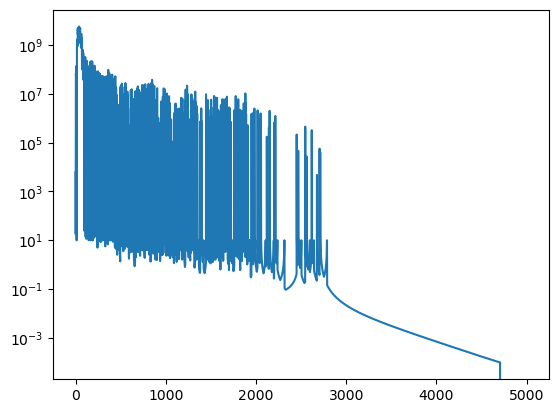

In [25]:
plt.plot(error_log)
plt.yscale('log')
# plt.xscale('log')
plt.show()

[[ 9.98808688e-01 -4.92634443e-05 -1.79643865e-05 ...  1.18543472e-02
   1.08399993e-02 -1.25748495e-02]
 [-4.92634443e-05  9.98747637e-01 -7.78632784e-05 ... -1.84566744e-02
   2.76694865e-02 -1.27312491e-02]
 [-1.79643865e-05 -7.78632784e-05  9.98819168e-01 ...  2.82333215e-02
   2.03685164e-02 -1.09406249e-02]
 ...
 [ 1.18543472e-02 -1.84566744e-02  2.82333215e-02 ...  9.98779126e-01
   2.51661044e-06 -4.13712739e-05]
 [ 1.08399993e-02  2.76694865e-02  2.03685164e-02 ...  2.51661044e-06
   9.98830220e-01  1.99079415e-05]
 [-1.25748495e-02 -1.27312491e-02 -1.09406249e-02 ... -4.13712739e-05
   1.99079415e-05  9.98728343e-01]]


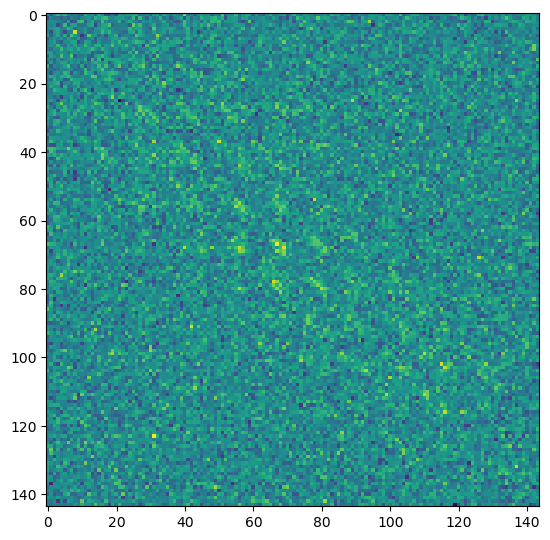

In [26]:
print (ZZT)
# iw = fpl.ImageWidget(ZZT, cmap="viridis", histogram_widget=False)
# iw.show()

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(ZZT[:n_pixels,n_lags*n_pixels:,])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/ZZT_{fig_label}.png')
plt.show()

[[0.17388229 0.07531196 0.0078069  ... 0.00634585 0.06400412 0.        ]
 [0.07531196 0.29598722 0.         ... 0.0652752  0.19074411 0.03015366]
 [0.0078069  0.         0.13678476 ... 0.04273693 0.0005275  0.01079198]
 ...
 [0.00634585 0.0652752  0.04273693 ... 0.23467151 0.00058647 0.10045283]
 [0.06400412 0.19074411 0.0005275  ... 0.00058647 0.34877111 0.16347646]
 [0.         0.03015366 0.01079198 ... 0.10045283 0.16347646 0.2345637 ]]


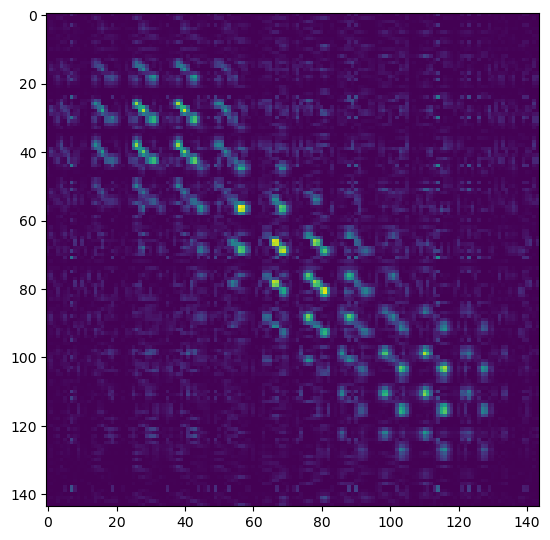

In [27]:
HHT = covariance_matrix(H)
print (HHT)
# iw = fpl.ImageWidget(YTY, cmap="viridis", histogram_widget=False)
# iw.show()

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(np.abs(HHT[:n_pixels,n_lags*n_pixels:]))
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/HHT_{fig_label}.png')
plt.show()

In [28]:
H_sum = np.zeros((n_pixels,k))
if n_lags==0:
    H_sum += H
else:
    for lag in range(0,n_lags+1):
        H_sum[:,:] += H[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)

In [29]:
image_array = []
for entry in range(0,k):

    snapshot = unvec.transform(H_sum[:,entry])
    image_array += [snapshot]

# F_rgba = spatial_to_rgba(np.array(image_array), 90)
# for c in F_rgba:
#     plt.imshow(c, alpha=0.3)
# plt.show()

# fig, ax = plt.subplots(k, 1, figsize=(6.4, k * 4.8))
# for row in range(0,k):
#     ax[row].imshow(image_array[row])
# plt.show()

In [30]:
from sklearn.metrics.pairwise import cosine_similarity

S_vec = vectorizer.fit_transform(source_footprints).T
print (f"S_vec.shape = {S_vec.shape}")

if simulation:
    cluster_matching = []
    selected_cluster = []
    for src in range(0,n_sources):
        max_corr = 0.
        pair_indices = []
        for cluster in range(0,k):
            if cluster in selected_cluster: 
                continue
            corr = S_vec[src] @ H_sum[:,cluster].T / np.sqrt(H_sum[:,cluster] @ H_sum[:,cluster].T * S_vec[src] @ S_vec[src].T)
            if corr > max_corr:
                max_corr = corr
                pair_indices = [src, cluster]
        cluster_matching += [pair_indices]
        selected_cluster += [pair_indices[1]]
    print (f"cluster_matching = {cluster_matching}")

S_vec.shape = (10, 144)
cluster_matching = [[0, 4], [1, 3], [2, 7], [3, 2], [4, 0], [5, 9], [6, 1], [7, 8], [8, 6], [9, 5]]


(144, 10)
(144, 1000)
(10, 1000)
(10, 996)


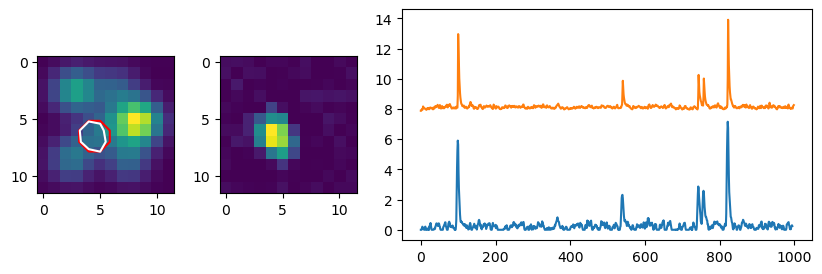

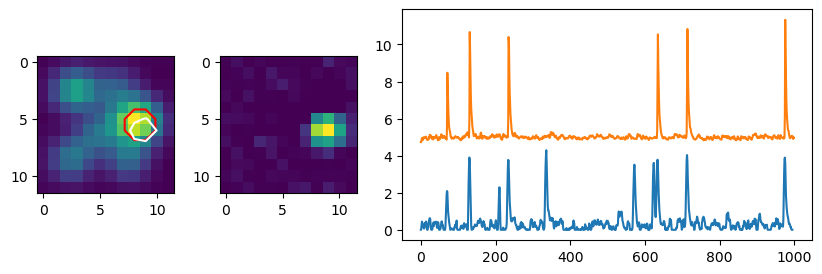

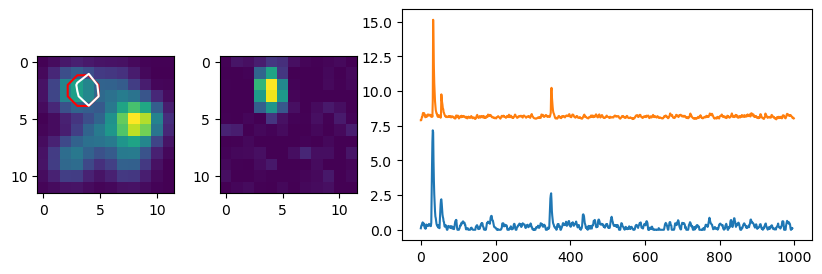

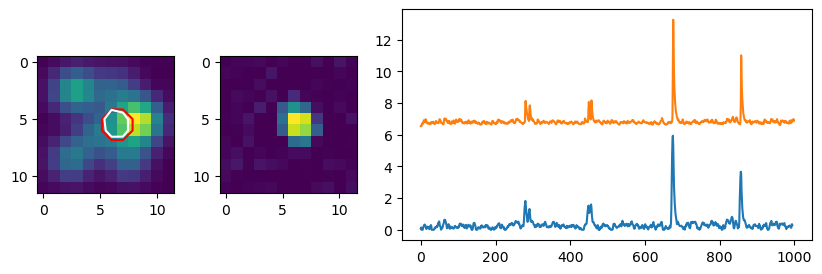

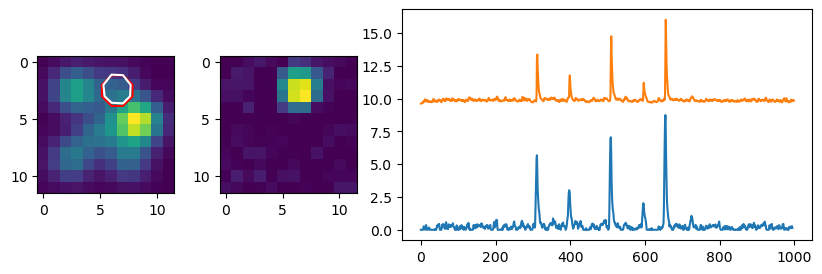

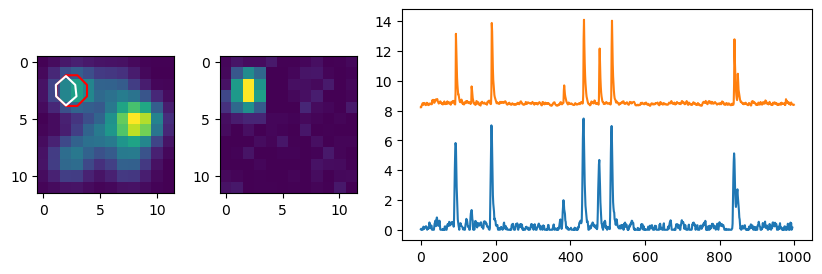

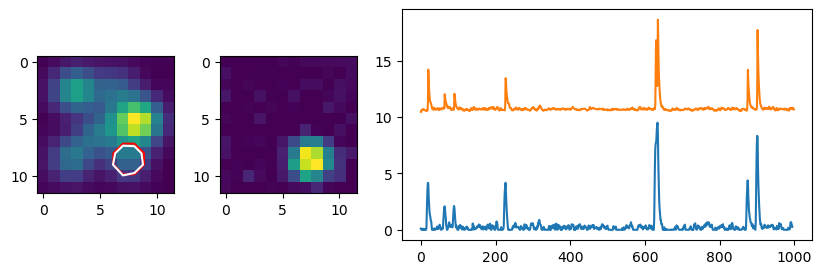

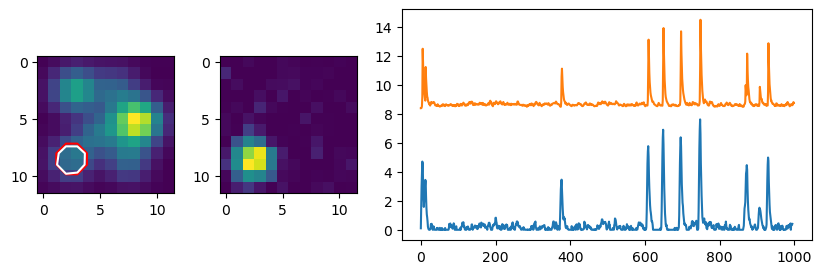

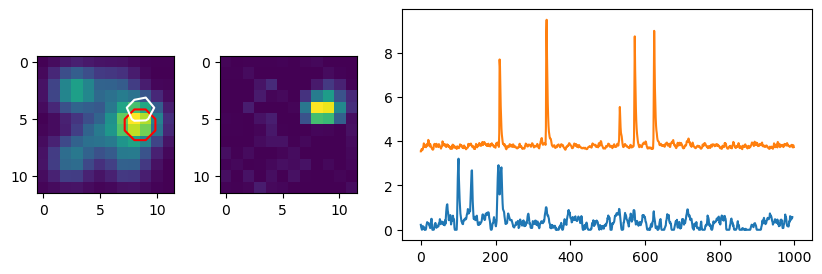

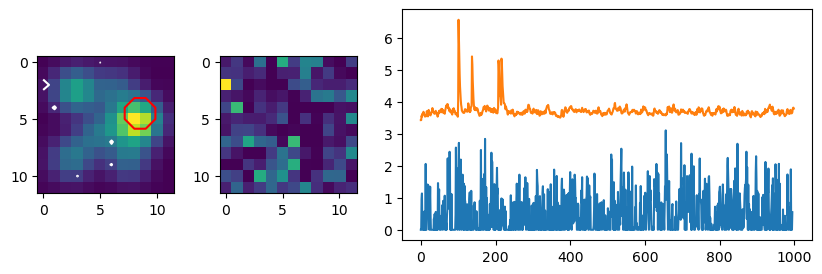

matching_score / truth_score = 0.745103637880512


In [31]:
print (H_sum.shape)
print (X.shape)
print (traces.shape)

T = H.T @ Z
T_sorted = np.zeros_like(traces)
print (T.shape)

if simulation:
    for src in range(0,n_sources):
        truth_norm = np.sum(traces[src])
        cluster = cluster_matching[src][1]
        reco_norm = np.sum(T[cluster])
        T[cluster] = T[cluster] * truth_norm / reco_norm
        T_sorted[src,n_lags*lag_time:] = T[cluster]

T = T.clip(0)

matching_score = 0.
truth_score = 0.
reco_levels = [0.60]
truth_levels = [0.60]
if simulation:
    for src in range(0,n_sources):
        fig, ax = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 1, 3]})
        cluster = cluster_matching[src][1]
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(source_footprints[src], levels=truth_levels, colors='r')
        ax[0].contour(image_array[cluster] / np.max(image_array[cluster]), levels=reco_levels, colors='w')
        ax[1].imshow(image_array[cluster])
        ax[2].plot(T[cluster], label="reconstruction")
        ax[2].plot(traces[src] + 1.1*np.max(T[cluster]), label="truth")
        # ax[2].legend()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_{fig_label}.png')
        plt.show()

        matching_score += T[cluster].T @ traces[src,n_lags*lag_time:]
        truth_score += np.sqrt(traces[src,n_lags*lag_time:].T @ traces[src,n_lags*lag_time:] * T[cluster].T @ T[cluster])

    print (f"matching_score / truth_score = {matching_score / truth_score}")
else:
    for src in range(0,k):
        fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(image_array[src], levels=reco_levels, colors='w')
        ax[1].imshow(image_array[src])
        ax[2].plot(T[src])
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_{fig_label}.png')
        plt.show()



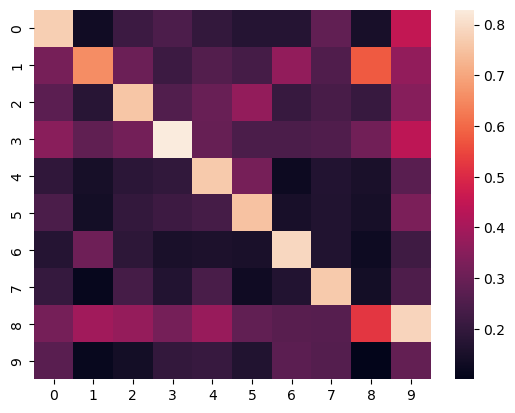

In [32]:
if simulation:
    sns.heatmap(cosine_similarity(T_sorted, traces))
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/CCA_cos_similarity_noise_multiple.png')

In [33]:

# iw = fpl.ImageWidget(image_array, cmap="viridis", histogram_widget=False)
# iw.show()

In [34]:
def cross_correlation(x, y, mode='full', normalize=False):
    """
    Compute the cross-correlation between two 1D signals.

    Parameters:
    - x, y: Input 1D numpy arrays.
    - mode: 'full', 'valid', or 'same' (passed to np.correlate).
    - normalize: If True, normalize the correlation to get correlation coefficient.

    Returns:
    - lags: Array of lag indices.
    - corr: Cross-correlation values.
    """
    x = np.asarray(x)
    y = np.asarray(y)
    
    if normalize:
        x = (x - np.mean(x)) / (np.std(x) + 1e-10)
        y = (y - np.mean(y)) / (np.std(y) + 1e-10)

    corr = np.correlate(x, y, mode=mode)
    lags = np.arange(-len(x) + 1, len(y)) if mode == 'full' else np.arange(len(corr))
    
    return lags, corr

(144, 10)
(5, 144, 996)
pix0 = 43
pix1 = 31


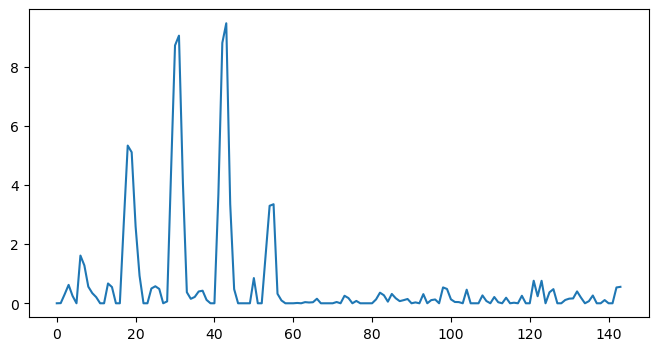

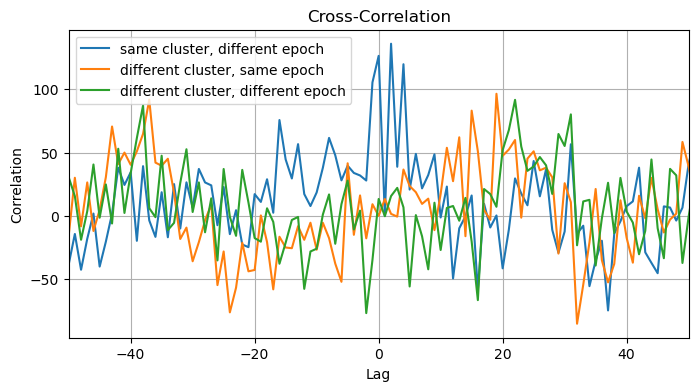

In [35]:
print (H_sum.shape)
print (P.shape)

k_select = 0
k_cluster = H_sum[:,k_select]
pix0 = np.argsort(k_cluster)[-1]
pix1 = np.argsort(k_cluster)[-2] 
print (f"pix0 = {pix0}")
print (f"pix1 = {pix1}")

plt.figure(figsize=(8, 4))
plt.plot(k_cluster)
plt.show()

k_select = 1
k_cluster = H_sum[:,k_select]
pix2 = np.argsort(k_cluster)[-1]
pix3 = np.argsort(k_cluster)[-2]

time_profile_pix0 = Pw[0,pix0,:]
time_profile_pix1 = Pw[1,pix1,:]
time_profile_pix2 = Pw[0,pix2,:]
time_profile_pix3 = Pw[1,pix3,:]

# plt.scatter(time_profile_pix0, time_profile_pix1, marker='o')
# plt.scatter(time_profile_pix1, time_profile_pix2, marker='o')
# plt.show()

# fig, ax = plt.subplots(1, 1, figsize=(10, 5))
# ax.plot(time_profile_pix1)
# ax.plot(time_profile_pix2)
# plt.show()

lags_00, corr_00 = cross_correlation(time_profile_pix0, time_profile_pix0)
lags_01, corr_01 = cross_correlation(time_profile_pix0, time_profile_pix1)
lags_02, corr_02 = cross_correlation(time_profile_pix0, time_profile_pix2)
lags_03, corr_03 = cross_correlation(time_profile_pix0, time_profile_pix3)

plt.figure(figsize=(8, 4))
plt.plot(lags_01, corr_01, label='same cluster, different epoch')
plt.plot(lags_02, corr_02, label='different cluster, same epoch')
plt.plot(lags_03, corr_03, label='different cluster, different epoch')
plt.title("Cross-Correlation")
plt.xlabel("Lag")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.xlim(-50, 50)
plt.show()